You will work with **2,284 weekly atmospheric CO₂ timestamps (1958–2001)** from the
`statsmodels` Mauna Loa dataset. There are **59 missing readings**. We also supply a
**512 × 512 grayscale camera image** from `skimage.data.camera()`.

Both assets are **bundled in `data/`**. No internet connection or API key is needed.
This is historical environmental data, **not current CO₂ readings**.

### Before running
    Install Python 3.10+ and the packages listed in `requirements.txt`.
    From the repository root, run `pip install -r requirements.txt` once.
    In Jupyter, choose **Kernel → Restart & Run All** to check the environment.

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when you launch Jupyter from the repository root or notebooks/ folder.
def data_path(filename):
    # Search for the data folder from the current
    # working directory up to the repository root.
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        f"Current directory: {Path.cwd()}"
    )

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 105})

In [12]:
import scipy
import PIL
print('numpy:', np.__version__)
print('pandas:', pd.__version__)
print('scipy:', scipy.__version__)
print('Pillow:', PIL.__version__)

numpy: 2.4.6
pandas: 3.0.3
scipy: 1.17.1
Pillow: 12.2.0


### 1. Audit the entire weekly dataset
    A data audit comes before interpolation, modelling, or making claims.

In [13]:
df = (pd.read_csv(data_path('MaunaLoa_CO2_Full.csv'), parse_dates=['date'])
        .set_index('date').sort_index())
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == 2284, 'Please use the supplied full historical dataset.'
assert int(df['co2_ppm'].isna().sum()) == 59
print('Rows:', len(df), '| Missing:', df['co2_ppm'].isna().sum())
print('Period:', df.index.min().date(), 'to', df.index.max().date())
display(df.head())

Rows: 2284 | Missing: 59
Period: 1958-03-29 to 2001-12-29


,co2_ppm
date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


,total_rows,observed_rows,missing_rows,missing_percent,minimum_ppm,maximum_ppm
0,2284,2225,59,2.58,313.0,373.9


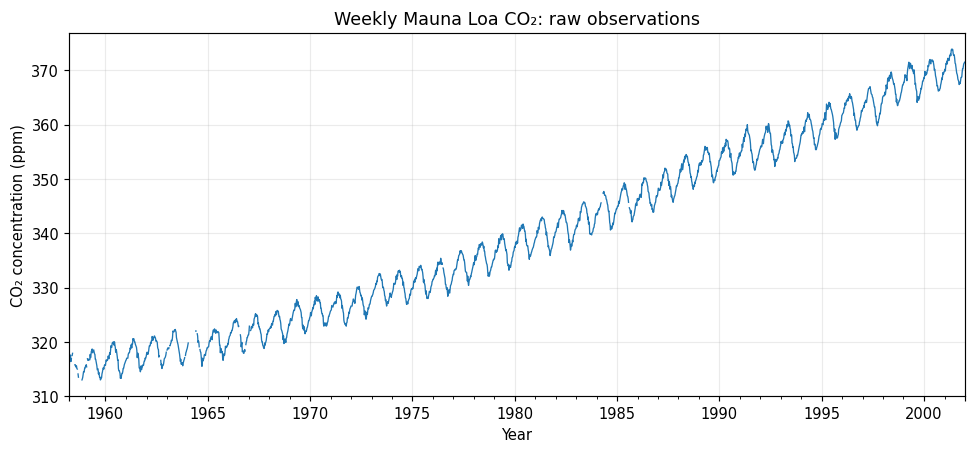

In [14]:
audit = pd.DataFrame({
    'total_rows': [len(df)],
    'observed_rows': [df.co2_ppm.notna().sum()],
    'missing_rows': [df.co2_ppm.isna().sum()],
    'missing_percent': [100 * df.co2_ppm.isna().mean()],
    'minimum_ppm': [df.co2_ppm.min()],
    'maximum_ppm': [df.co2_ppm.max()],
})
display(audit.round(2))

ax = df.co2_ppm.plot(lw=0.9, color='tab:blue', title='Weekly Mauna Loa CO₂: raw observations')
ax.set(xlabel='Year', ylabel='CO₂ concentration (ppm)')
plt.show()

### 2. Inspect the image used in Activity 3B

Image shape: (512, 512) | dtype: uint8


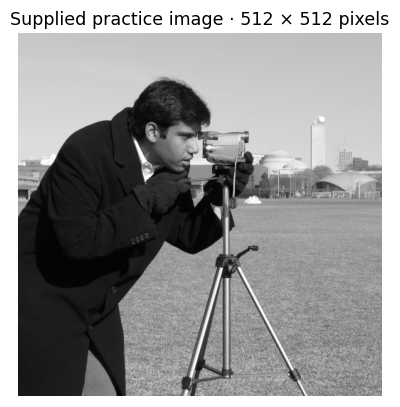

In [16]:
from PIL import Image
image = np.asarray(Image.open(data_path('Camera_Practice_Image.png')).convert('L'))
assert image.shape == (512, 512)
print('Image shape:', image.shape, '| dtype:', image.dtype)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Supplied practice image · 512 × 512 pixels')
plt.axis('off')
plt.show()

### 3. Two tiny SciPy warm-ups
    These are **demonstrations**, not substitutes for the full-data investigations.

In [17]:
from scipy.integrate import quad
from scipy.linalg import solve

area, numerical_error = quad(lambda x: 4*x**2 + 2, 0, 2)
print('Area under f(x) = 4x² + 2 from 0 to 2:', round(area, 4))

A = np.array([[2.0, 1.0], [1.0, -1.0]])
b = np.array([7.0, 1.0])
print('Solution to A @ x = b:', solve(A, b))

Area under f(x) = 4x² + 2 from 0 to 2: 14.6667
Solution to A @ x = b: [2.66666667 1.66666667]


### Discuss before continuing
    1. Why must we preserve the original raw readings before filling missing values?
    2. What does **ppm** measure? What would **ppm × years** mean?
    3. Why is a scientific image suitable for NumPy/SciPy processing?

    **Next:** Activity 1 uses every weekly timestamp to calculate an accumulated CO₂ anomaly.